# Student Admission Probability Analyzer

Predicts the probability a student is admitted using **Bayes' theorem** (Gaussian Naive Bayes) instead of a complex ML model, based on:
- CGPA
- Entrance Score
- 12th Percentage
- Extracurricular Score

Also computes mean, variance, quantiles, covariance, and feature distributions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 500

cgpa = np.clip(np.random.normal(7.5, 1.1, n), 4, 10)
entrance = np.clip(np.random.normal(75, 12, n), 30, 100)
twelfth = np.clip(np.random.normal(80, 8, n), 50, 100)
extra = np.clip(np.random.normal(60, 20, n), 0, 100)

z = (0.9*(cgpa-7.5) + 0.05*(entrance-75) + 0.04*(twelfth-80) + 0.02*(extra-60)) - 0.3
prob = 1/(1+np.exp(-z))
admitted = (np.random.rand(n) < prob).astype(int)

df = pd.DataFrame({
    "CGPA": cgpa.round(2),
    "EntranceScore": entrance.round(1),
    "TwelfthPercentage": twelfth.round(1),
    "ExtracurricularScore": extra.round(1),
    "Admitted": admitted
})
df.head()

,CGPA,EntranceScore,TwelfthPercentage,ExtracurricularScore,Admitted
0,8.05,86.1,91.2,75.6,1
1,7.35,97.9,87.4,49.0,1
2,8.21,58.2,80.5,43.6,0
3,9.18,81.8,74.8,59.9,1
4,7.24,67.2,85.6,56.6,0


## Descriptive statistics

In [2]:
feats = ["CGPA", "EntranceScore", "TwelfthPercentage", "ExtracurricularScore"]

print("Mean:\n", df[feats].mean(), "\n")
print("Variance:\n", df[feats].var(), "\n")
print("Quantiles (25/50/75%):\n", df[feats].quantile([0.25, 0.5, 0.75]), "\n")
print("Covariance matrix:\n", df[feats].cov())

Mean:
 CGPA                     7.50106
EntranceScore           75.30700
TwelfthPercentage       80.86460
ExtracurricularScore    60.49740
dtype: float64 

Variance:
 CGPA                      1.122024
EntranceScore           133.599730
TwelfthPercentage        65.152271
ExtracurricularScore    371.353039
dtype: float64 

Quantiles (25/50/75%):
         CGPA  EntranceScore  TwelfthPercentage  ExtracurricularScore
0.25  6.7300         67.875             75.200                47.800
0.50  7.5100         75.300             81.000                59.800
0.75  8.2025         82.825             86.025                73.975 

Covariance matrix:
                           CGPA  EntranceScore  TwelfthPercentage  \
CGPA                  1.122024      -0.922524          -0.529353   
EntranceScore        -0.922524     133.599730           7.037342   
TwelfthPercentage    -0.529353       7.037342          65.152271   
ExtracurricularScore  1.449279      -6.033729          -3.408609   

             

## Feature distributions

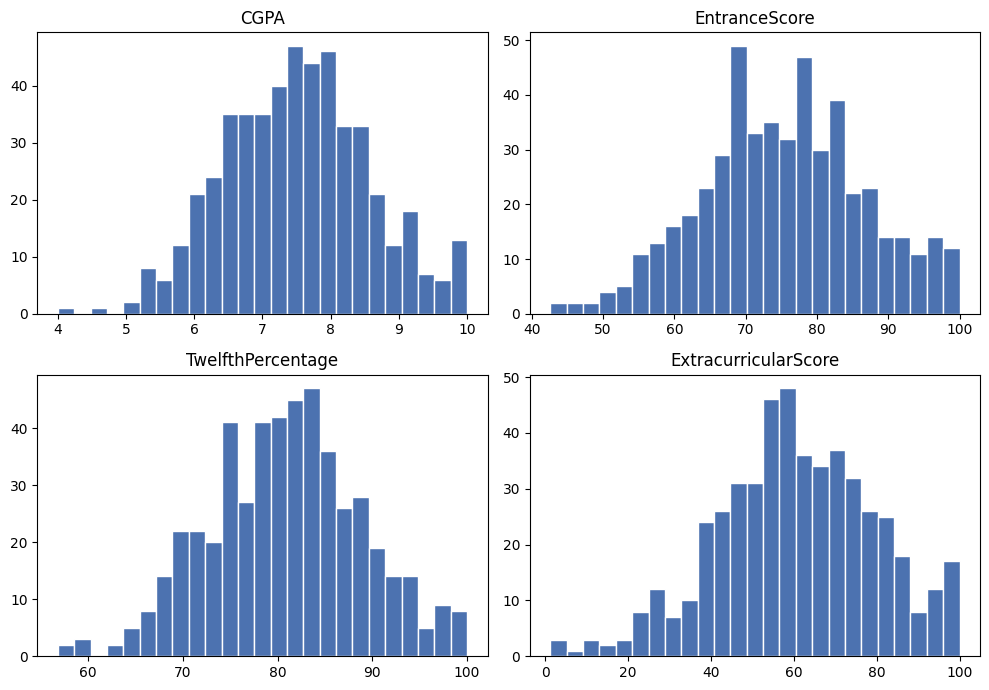

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.flat, feats):
    ax.hist(df[f], bins=25, color="#4C72B0", edgecolor="white")
    ax.set_title(f)
plt.tight_layout()
plt.show()

## Bayes' theorem: probability of admission

We treat "Admitted" as a class variable and model each feature as Gaussian, conditioned on class.
By Bayes' theorem:

$$P(\text{Admit} \mid X) = \frac{P(X \mid \text{Admit})\, P(\text{Admit})}{P(X)}$$

Assuming feature independence given the class (Naive Bayes), $P(X\mid \text{Admit})$ is the product of per-feature Gaussian likelihoods. We never need $P(X)$ explicitly — we compute both class scores and normalize.

In [4]:
def gaussian_pdf(x, mean, var):
    return (1.0 / np.sqrt(2*np.pi*var)) * np.exp(-((x-mean)**2)/(2*var))

class GaussianNBAdmission:
    def fit(self, df, feats, target="Admitted"):
        self.feats = feats
        self.prior1 = df[target].mean()
        self.prior0 = 1 - self.prior1
        g1, g0 = df[df[target]==1], df[df[target]==0]
        self.mean1, self.var1 = g1[feats].mean(), g1[feats].var()
        self.mean0, self.var0 = g0[feats].mean(), g0[feats].var()
        return self

    def predict_proba(self, student: dict):
        like1 = self.prior1
        like0 = self.prior0
        for f in self.feats:
            like1 *= gaussian_pdf(student[f], self.mean1[f], self.var1[f])
            like0 *= gaussian_pdf(student[f], self.mean0[f], self.var0[f])
        return like1 / (like1 + like0)

model = GaussianNBAdmission().fit(df, feats)

# Example from the project brief
example = {"CGPA": 8.7, "EntranceScore": 85, "TwelfthPercentage": 91, "ExtracurricularScore": 60}
p = model.predict_proba(example)
print(f"Probability of Admission = {p*100:.1f}%")

Probability of Admission = 77.8%


## Try your own student

Edit the values below and re-run to get a probability.

In [5]:
my_student = {"CGPA": 8.0, "EntranceScore": 78, "TwelfthPercentage": 85, "ExtracurricularScore": 55}
p = model.predict_proba(my_student)
print(f"Probability of Admission = {p*100:.1f}%")

Probability of Admission = 54.8%
